# Bisecting K-Means

- construir los grupos por divisiones

--------

## Bisecting K-Means

- Es un método **jerárquico divisivo**
- No intenta obtener los K clústers en una sola ejecución
- Cada división utiliza un problema de 2-means dentro de un clúster padre
- Construye la solución secuencialmente por particiones binarias
- Cada incremento de K aparece al dividir uno de los clusters existentes: los nuevos clusters aparecen al subdividir grupos previamente existentes


-----

## Algoritmo

1. Comenzar con todas las instancias en un clúster
2. Elegir el clúster padre C que será dividido
3. Ejecutar 2-means varias veces sobre C
4. Evaluar las 2 subparticiones obtenidas
5. Conservar la mejor división C --> $C_1$, $C_2$
6. Seleccionar el siguiente clúster padre
7. Repetir hasta obtener k clústers


-----

# Comparación

| Método | Representante | Criterio | Rasgo distintivo
| -- | -- | -- | -- |
| K-Means | media $c_k$ | $L_2$ | simple y eficiente |
| k-Medoids | medoid (instancia) | $L_1$,$L_2$ | + robusto, + costoso |
| k-Medians | mediana por caract. | $L_1$ | robusto a extremos |
| Bisecting K-means | $c_k$ de divisiones 2-means | div. binarias | contruye K grupos secuencialmente |


-----

# Código

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import BisectingKMeans
from sklearn.pipeline import make_pipeline

plt.style.use('dark_background') # poner modo oscuro los plots

RAND_STATE = 42 # para reproducibilidad, se usará 42 como random state
K = 3   

------------

## Pipeline

- Usamos *make_pipeline* para crear un pipeline de escalamiento y luego entrenamiento
- Así que al llamar a fit o predict con datos sin escalar, aplica automáticamente el escalador adecuado.

In [79]:
pipeline = make_pipeline(
    MinMaxScaler(),
    BisectingKMeans(
        n_clusters=K,
        random_state=RAND_STATE,
        bisecting_strategy="biggest_inertia"
    )
)

-------

## 2. Cargar iris

In [88]:
# los datos a usar:

iris = load_iris(as_frame=True)
iris.data.head()

columns = ['sepal length (cm)', 'sepal width (cm)']

X = iris.data[columns].copy()
X

,sepal length (cm),sepal width (cm)
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6
...,...,...
145,6.7,3.0
146,6.3,2.5
147,6.5,3.0
148,6.2,3.4


-------


## 3. Viendo nuestros datos

Text(0, 0.5, 'sepal width (cm)')

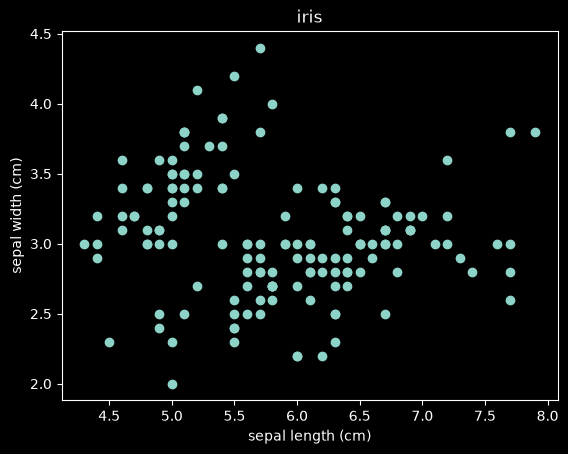

In [81]:
plt.scatter(
    X['sepal length (cm)'],
    X['sepal width (cm)']
)
plt.title("iris")
plt.xlabel(columns[0])
plt.ylabel(columns[1])

-------

## 4. Entrenando el modelo

`fit(X)` ajusta todo el pipeline, paso por paso y en orden:
- MinMaxScaler aprende los mínimos y máximos de cada columna y transforma X.
- BisectingKMeans recibe los datos transformados y aprende los clusters.

Es decir, el escalador se ajusta primero y el algoritmo de clustering después.

In [82]:
pipeline.fit(X)

# si queremos, podemos acceder a cada paso así
scaler = pipeline.named_steps["minmaxscaler"]   # El escalador
# model = pipeline.named_steps["bisectingkmeans"]  # El clusterizador

inercia = pipeline.named_steps["bisectingkmeans"].inertia_
scaled_centroids = pipeline.named_steps["bisectingkmeans"].cluster_centers_
centroids = scaler.inverse_transform(scaled_centroids)

print(inercia)
print(centroids)

4.679567264337682
[[6.60746269 2.95373134]
 [5.51515152 2.67272727]
 [5.036      3.45      ]]


-----

## 5. Guardando los clusters asignados a los datos

In [83]:
labels = pipeline.named_steps['bisectingkmeans'].labels_

X['cluster'] = labels

X.sample(5)

,sepal length (cm),sepal width (cm),cluster
88,5.6,3.0,1
9,4.9,3.1,2
32,5.2,4.1,2
68,6.2,2.2,0
6,4.6,3.4,2


-----

## 6. Visualizando los clusters

In [84]:
scaled_centroids.shape

(3, 2)

Text(0, 0.5, 'sepal width (cm)')

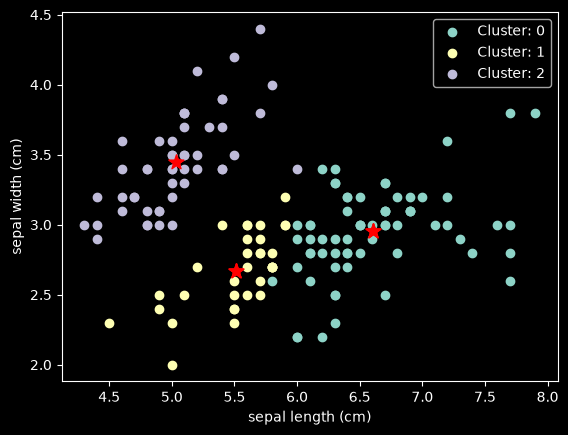

In [85]:
for cluster in range(K):

    mask = X['cluster'] == cluster    
    plt.scatter(
        X[mask]['sepal length (cm)'],
        X[mask]['sepal width (cm)'],
        label = f'Cluster: {cluster}'
        )

    plt.scatter(
        centroids[:, 0],
        centroids[:, 1],
        marker='*', s=122, c='red'
    )

plt.legend()
plt.xlabel(columns[0])
plt.ylabel(columns[1])

--------

### 7. Predecir clusters para datos nuevos


In [90]:
nuevos = pd.DataFrame(
    [
        [5.1, 3.5],
        [6.7, 3.0],
        [5.8, 2.7],
    ],
    columns=columns
)

clusters_nuevos = pipeline.predict(nuevos)
clusters_nuevos

array([2, 0, 1], dtype=int32)

---------